## FinBERT VS users classification

In this part I am going to compare the messages classified by finBERT with the classification made by the users.

In [1]:
import pandas as pd
fin_classified = pd.read_csv("data/finBer_classification_Bullish.csv")
user_annotated = pd.read_csv("data/BTC_Sentiment_from_feature.csv")

In [2]:
# 1. Trouver les ids communs
ids_communs = user_annotated["message_id"].isin(fin_classified["message_id"])
df1_communs = user_annotated[ids_communs]
# 2. Filtrer : sentiment non NaN dans df1
mask = df1_communs["sentiment"].notna()
df1_filtre = df1_communs[mask]

In [9]:
# 3. Fusionner avec df2 sur id pour comparer
df2_ids = fin_classified[fin_classified["message_id"].isin(df1_filtre["message_id"])]
fusion = df1_filtre.merge(df2_ids, on="message_id", suffixes=("_df1", "_df2"))

# 4. Comparer les valeurs de sentiment
mask = (
    ((fusion["sentiment_df1"] == "Bullish") & (fusion["sentiment_df2"] == "positive")) |
    ((fusion["sentiment_df1"] == "Bearish") & (fusion["sentiment_df2"] == "negative"))
)
resultats = fusion[mask]

# 5. Afficher les résultats
print(f"Total selected : {len(fusion)}")
print(f"Match Bullish/positive or Bearish/negative : {len(resultats)}")
#print(resultats[["message_id", "sentiment_df1", "sentiment_df2"]])
print("unlabeled data:")
print((fusion["sentiment_df1"] == "not_labeled").sum())


Total selected : 63822
Match Bullish/positive or Bearish/negative : 2364
unlabeled data:
36655


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 3044.72it/s]


Total messages: 63822
Période: 2017-11-02 22:12:47+00:00 → 2017-12-15 21:31:25+00:00

Répartition:
sentiment
neutral    24885
bullish    22602
bearish    16335
Name: count, dtype: int64

Indicateur généré: 41 points
                       date  total  bullish  bearish  neutral  ratio_bullish  \
0 2017-11-02 22:12:47+00:00    877      346      193      338       0.394527   
1 2017-11-03 22:12:47+00:00    572      238      116      218       0.416084   
2 2017-11-04 22:12:47+00:00    689      235      149      305       0.341074   
3 2017-11-05 22:12:47+00:00    975      349      299      327       0.357949   
4 2017-11-06 22:12:47+00:00    629      218      168      243       0.346582   
5 2017-11-07 22:12:47+00:00   1385      509      340      536       0.367509   
6 2017-11-08 22:12:47+00:00    696      245      162      289       0.352011   
7 2017-11-09 22:12:47+00:00   1032      354      296      382       0.343023   
8 2017-11-10 22:12:47+00:00    867      317      227      323   

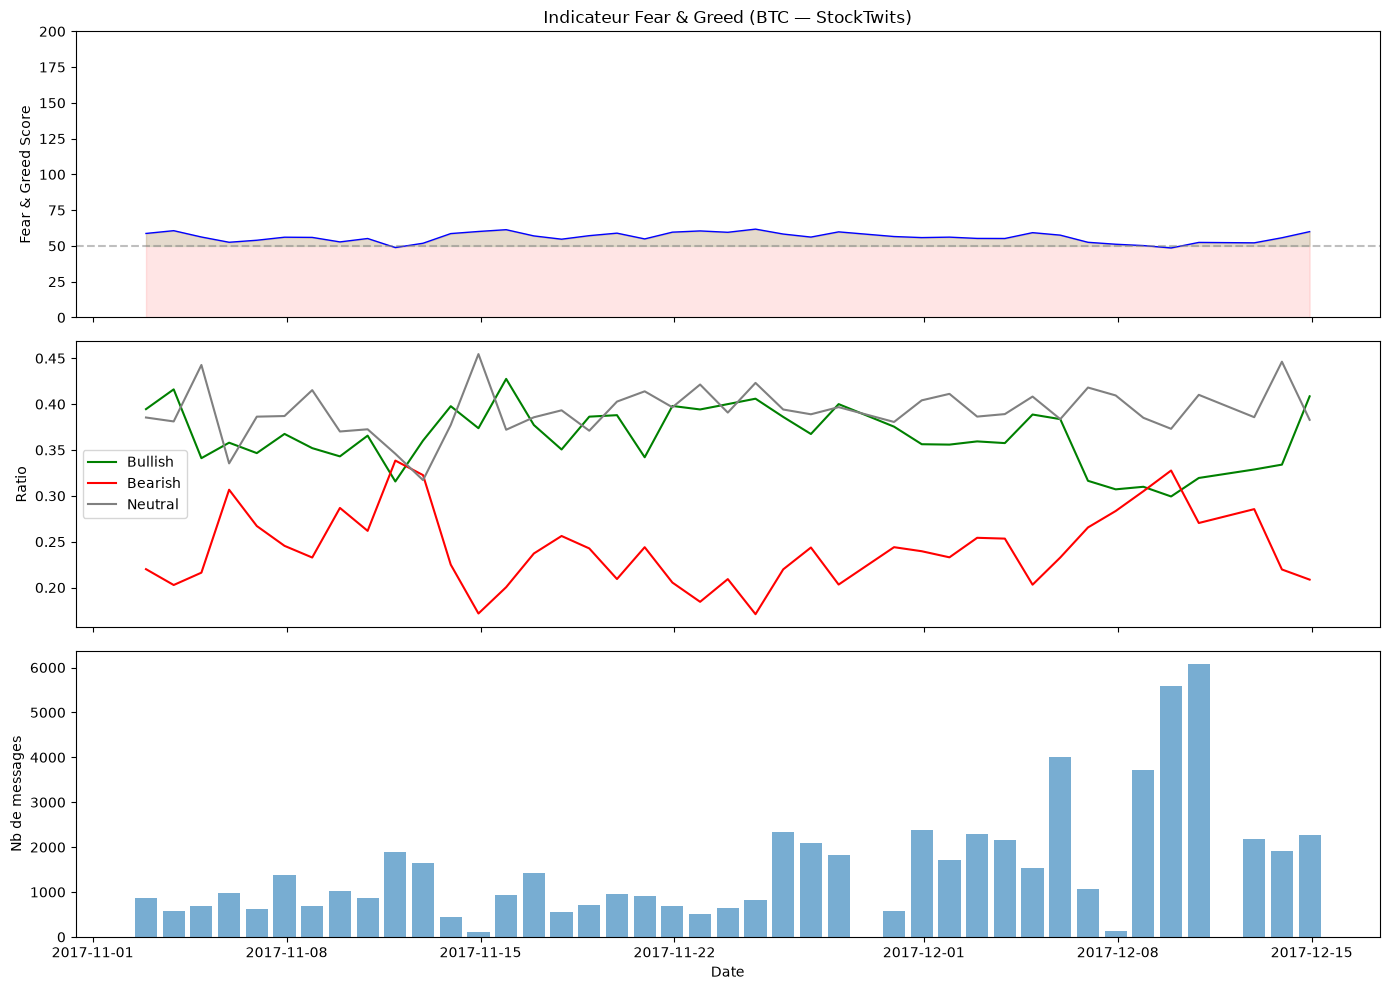

In [ ]:

# Indicateur Fear & Greed — Ratio Bullish/Total (fenêtre glissante)

import pandas as pdx
import numpy as np
from transformers import pipeline
from datetime import timedelta
import torch   


# 1. Chargement du modèle fine-tuné
from huggingface_hub import HfApi
import os

# Connectez-vous (une seule fois)
#from dotenv import load_dotenv
#load_dotenv()
#os.environ["HF_TOKEN"]

clf = pipeline(
    "text-classification",
    model="mawuenar/finbert-tweets-BTX_V3",
    #device=1,  # GPU si dispo, -1 pour CPU
)


# 2. Chargement des données StockTwits

# Ajuste le chemin et les noms de colonnes selon ton CSV
df = fusion

# Colonne texte (à adapter)
text_col = "message_body"

# Colonne date (à adapter) — format attendu : datetime
date_col = "created_at"
df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).reset_index(drop=True)

print(f"Total messages: {len(df)}")
print(f"Période: {df[date_col].min()} → {df[date_col].max()}")

#df = df.head(10000)
#print(f"Échantillon: {len(df)} messages (test)")
# 3. Classification par le modèle fine-tuné

def classify_batch(texts, batch_size=64):
    Classifie par lots pour éviter les OOM.
    results = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        preds = clf(batch, truncation=True, max_length=128)
        results.extend(preds)
    return results

# Classification (long sur CPU, rapide sur GPU, mais malheureusement je n'en ai pas D': )
predictions = classify_batch(df[text_col].tolist())

# Extraction du label et du score
labels = [p["label"] for p in predictions]
scores = [p["score"] for p in predictions]

df["sentiment"] = labels
df["confidence"] = scores

print(f"\nRépartition:")
print(df["sentiment"].value_counts())


# 4. Calcul du ratio bullish/total sur fenêtre glissante

def compute_fear_greed(df, date_col, window_days=7, step_days=1):    
    
    #    window_days : taille de la fenêtre (jours)
    #    step_days   : taille de glissement (en jours)
    
    #Retourne:
    #    DataFrame avec [date, total, bullish, bearish, neutral, 
    #                    ratio_bullish, ratio_bearish, fear_greed_score]
    
    results = []
    start = df[date_col].min()
    end = df[date_col].max()
    current = start

    while current <= end:
        window_end = current + timedelta(days=window_days)
        mask = (df[date_col] >= current) & (df[date_col] < window_end)
        window = df[mask]

        if len(window) == 0:
            current += timedelta(days=step_days)
            continue

        total = len(window)
        bullish = (window["sentiment"] == "bullish").sum()
        bearish = (window["sentiment"] == "bearish").sum()
        neutral = (window["sentiment"] == "neutral").sum()

        ratio_bullish = bullish / total
        ratio_bearish = bearish / total

        # Score Fear & Greed : 0 = peur max, 100 = greed max
        # (ratio_bullish - ratio_bearish) normalisé
        raw = ratio_bullish - ratio_bearish  # entre -1 et +1
        fear_greed_score = (raw + 1) / 2 * 100  # entre 0 et 100

        results.append({
            "date": current,
            "total": total,
            "bullish": bullish,
            "bearish": bearish,
            "neutral": neutral,
            "ratio_bullish": ratio_bullish,
            "ratio_bearish": ratio_bearish,
            "fear_greed_score": fear_greed_score,
        })

        current += timedelta(days=step_days)

    return pd.DataFrame(results)


# 5. Génération de l'indicateur

# Fenetre fixé à 1 jours, glissement de 1 jour, a tester en changeant la fenetre
fg = compute_fear_greed(df, date_col="created_at", window_days=1, step_days=1)

print(f"\nIndicateur généré: {len(fg)} points")
print(fg.head(10))
print(f"\nScore moyen: {fg['fear_greed_score'].mean():.1f}")
print(f"Score min:    {fg['fear_greed_score'].min():.1f} (peur max)")
print(f"Score max:    {fg['fear_greed_score'].max():.1f} (greed max)")


# 6. Sauvegarde

fg.to_csv("fear_greed_indicator.csv", index=False)
df[["sentiment", "confidence"]].to_csv("classified_tweets.csv", index=False)


# 7. Visualisation

import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Score Fear & Greed
axes[0].plot(fg["date"], fg["fear_greed_score"], color="blue", linewidth=1)
axes[0].axhline(50, color="gray", linestyle="--", alpha=0.5)
axes[0].fill_between(fg["date"], 0, fg["fear_greed_score"], alpha=0.1, color="red")
axes[0].fill_between(fg["date"], 50, fg["fear_greed_score"], alpha=0.1, color="green")
axes[0].set_ylabel("Fear & Greed Score")
axes[0].set_title("Indicateur Fear & Greed (BTC — StockTwits)")
axes[0].set_ylim(40, 80)

# Ratios
axes[1].plot(fg["date"], fg["ratio_bullish"], label="Bullish", color="green")
axes[1].plot(fg["date"], fg["ratio_bearish"], label="Bearish", color="red")
axes[1].plot(fg["date"], fg["neutral_count"] if "neutral_count" in fg.columns else fg["neutral"]/fg["total"], label="Neutral", color="gray")
axes[1].set_ylabel("Ratio")
axes[1].legend()

# Volume de messages
axes[2].bar(fg["date"], fg["total"], width=0.8, alpha=0.6)
axes[2].set_ylabel("Nb de messages")
axes[2].set_xlabel("Date")

plt.tight_layout()
plt.savefig("fear_greed_indicator.png", dpi=150)
plt.show()   

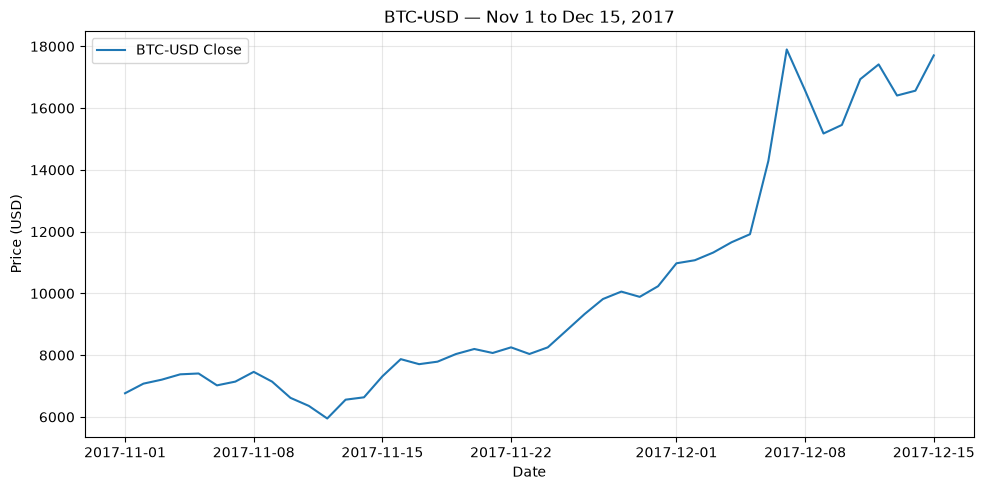

In [1]:
import yfinance as yf
import matplotlib.pyplot as plt

btc = yf.Ticker("BTC-USD")
df = btc.history(start="2017-11-01", end="2017-12-16")

plt.figure(figsize=(10, 5))
plt.plot(df.index, df["Close"], label="BTC-USD Close")
plt.title("BTC-USD — Nov 1 to Dec 15, 2017")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()   